# R3 — Kiểm tra dữ liệu và ERP đầu tiên tại Pz

Chọn kernel Python của `.venv`, rồi chạy lần lượt các ô từ trên xuống.
Notebook dùng dữ liệu v2 đã cleaning của nhóm; không thực hiện lại tiền xử lý.
Mục tiêu: kiểm tra một subject và vẽ ERP standard/target/distractor tại Pz.
Đây là hình khám phá của một người; bước tiếp theo là grand-average và SEM qua subject để làm F2.


In [1]:
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

from eegproj.config import find_root, load_config
from eegproj.evaluation.erp import _usable_release_log

ROOT = find_root()
CONFIG = load_config(ROOT)
DATA_DIR = ROOT / CONFIG["paths"]["derivatives"]

## 1. Chọn subject hợp lệ

Dùng log đi kèm bản dữ liệu đã tải, chỉ giữ `pipeline_version = 2` và `excluded_subject = False`.
Hiện bản phát hành có 35 người dùng được. `visual_review=pending` là kiểm tra QC bằng mắt còn chờ R2, không phải một tiêu chí tự loại thêm subject.


In [2]:
usable_log = _usable_release_log(ROOT, CONFIG)
subjects = usable_log["subject"].tolist()
assert subjects, "Không có subject hợp lệ trong log dữ liệu."
missing = [
    subject for subject in subjects if not (DATA_DIR / f"{subject}_task-{CONFIG['dataset']['task']}_epo.fif").is_file()
]
assert not missing, f"Thiếu file epoch: {missing}"
print(f"Số subject dùng được: {len(subjects)}")
print(subjects)
display(usable_log[["subject", "visual_review", "flags"]].head())

Số subject dùng được: 35
['sub-01', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-15', 'sub-16', 'sub-18', 'sub-19', 'sub-20', 'sub-21', 'sub-22', 'sub-24', 'sub-25', 'sub-26', 'sub-27', 'sub-28', 'sub-29', 'sub-30', 'sub-31', 'sub-32', 'sub-33', 'sub-34', 'sub-36', 'sub-37', 'sub-38', 'sub-39', 'sub-40', 'sub-42']


,subject,visual_review,flags
0,sub-01,pending,hit_rate=0.77
2,sub-03,pending,NaN
3,sub-04,pending,NaN
4,sub-05,pending,NaN
5,sub-06,pending,NaN


## 2. Đọc và kiểm tra một subject

Bắt đầu với `sub-01`; có thể đổi `SUBJECT` sang một người trong danh sách trên.
Tham số tần số, epoch và baseline được đọc từ config. Các event trong FIF đã có tên `standard`, `target`, `distractor`.
Dữ liệu MNE lưu theo V; khi vẽ chuyển sang µV. Target phải có RT, hai loại còn lại không có RT vì chỉ giữ trial đúng hành vi.


In [3]:
SUBJECT = "sub-01"
assert SUBJECT in subjects, f"{SUBJECT} không thuộc danh sách dùng được."
epoch_path = DATA_DIR / f"{SUBJECT}_task-{CONFIG['dataset']['task']}_epo.fif"
epochs = mne.read_epochs(epoch_path, preload=True, verbose="error")
conditions = ("standard", "target", "distractor")
pre = CONFIG["preprocessing"]
assert np.isclose(epochs.info["sfreq"], pre["resample_sfreq"])
assert np.allclose([epochs.tmin, epochs.tmax], [pre["epoch"]["tmin"], pre["epoch"]["tmax"]])
assert epochs.baseline is not None and np.allclose(epochs.baseline, pre["epoch"]["baseline"])
assert set(epochs.event_id) == set(conditions)
assert "Pz" in epochs.ch_names
assert epochs.metadata is not None
assert {"subject", "onset_s", "block", "rt"} <= set(epochs.metadata.columns)
assert epochs.metadata["onset_s"].is_monotonic_increasing
is_target = epochs.events[:, 2] == epochs.event_id["target"]
assert epochs.metadata.loc[is_target, "rt"].between(CONFIG["behaviour"]["rt_min"], CONFIG["behaviour"]["rt_max"]).all()
assert epochs.metadata.loc[~is_target, "rt"].isna().all()
data = epochs.get_data()
assert np.isfinite(data).all()
assert np.max(np.ptp(data, axis=-1)) <= pre["epoch"]["reject_ptp_uv"] * 1e-6 * 1.00001
del data
counts = pd.Series({condition: len(epochs[condition]) for condition in conditions}, name="n_epochs")
assert counts.gt(0).all()
subject_log = usable_log.set_index("subject").loc[SUBJECT]
assert len(epochs.ch_names) == int(subject_log["n_channels"])
for condition in conditions:
    assert counts[condition] == int(subject_log[f"{condition}_after"])
print(f"{SUBJECT}: {len(epochs.ch_names)} kênh, {epochs.info['sfreq']:g} Hz, {len(epochs.times)} mẫu/epoch")
print(f"Epoch: {epochs.tmin * 1000:g} đến {epochs.tmax * 1000:g} ms")
display(counts.to_frame())
display(epochs.metadata.head())

sub-01: 127 kênh, 250 Hz, 251 mẫu/epoch
Epoch: -200 đến 800 ms


,n_epochs
standard,478
target,61
distractor,52


,subject,onset_s,block,rt
0,01,22.266,0,NaN
1,01,24.000,0,NaN
2,01,25.433,0,NaN
3,01,27.066,0,NaN
4,01,28.549,0,NaN


## 3. Vẽ ERP tại Pz

Mỗi đường là trung bình các trial của một điều kiện trong cùng subject.
Hình được lưu vào `figures/erp_exploration/` (đã gitignore) dưới dạng PNG 300 dpi và PDF.
Khi đọc hình, xem baseline trước kích thích, độ khác nhau giữa các điều kiện và thời điểm đỉnh dương. Chưa kết luận về P300 hay nhiễu vận động từ riêng một subject.


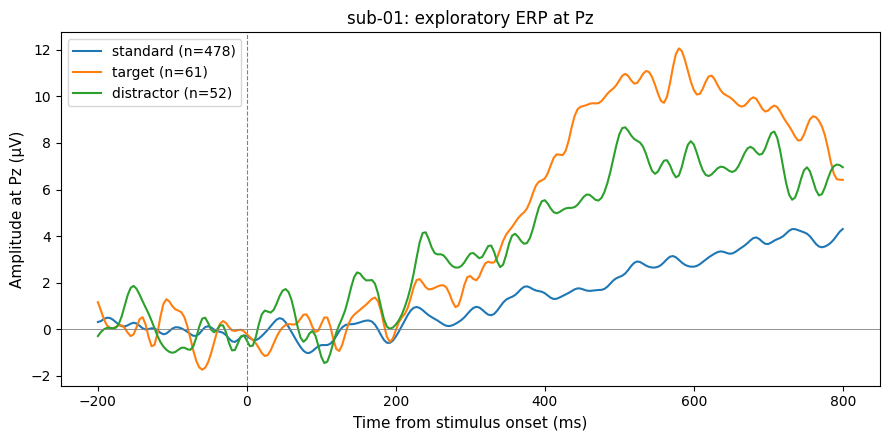

In [4]:
evokeds = {condition: epochs[condition].average() for condition in conditions}
fig, ax = plt.subplots(figsize=(9, 4.5))
for condition, evoked in evokeds.items():
    ax.plot(
        evoked.times * 1000,
        evoked.get_data(picks=["Pz"])[0] * 1e6,
        label=f"{condition} (n={counts[condition]})",
    )
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.6)
ax.set(
    xlabel="Time from stimulus onset (ms)",
    ylabel="Amplitude at Pz (µV)",
    title=f"{SUBJECT}: exploratory ERP at Pz",
)
ax.tick_params(labelsize=10)
ax.xaxis.label.set_size(11)
ax.yaxis.label.set_size(11)
ax.legend(fontsize=10)
fig.tight_layout()
figure_dir = ROOT / CONFIG["paths"]["figures"] / "erp_exploration"
figure_dir.mkdir(parents=True, exist_ok=True)
for suffix in ("png", "pdf"):
    output_path = figure_dir / f"{SUBJECT}_Pz_erp.{suffix}"
    fig.savefig(output_path, dpi=CONFIG["erp"]["figure_dpi"], bbox_inches="tight")
plt.show()

## Bước tiếp theo

- Tính ERP cho từng người trong toàn bộ danh sách hợp lệ, rồi lấy trung bình và SEM **qua subject** tại Pz/CPz/Cz.
- Tính difference wave target − standard và topomap theo protocol §9 để làm F2.
- Phối hợp R2 kiểm tra QC trước khi chốt kết quả.
- Trước khi commit, bật `nbstripout --install` theo CONTRIBUTING; không đưa hình và output chạy lên Git.
